# FS1 — K-Means trên RFM (tiền xử lý P-keep)

Thí nghiệm **FS1** (đối chứng): chỉ dùng Recency, Frequency, Monetary. Khác baseline ở tiền xử lý: giữ dòng trùng và mã dịch vụ, tách chứng từ C sang bảng riêng thay vì xóa. Cấu hình thử nghiệm, chưa phải quyết định chính thức của nhóm. Mọi chỉ số tính trên `X_scaled`.

## Params

In [1]:
RANDOM_STATE = 42
INIT = "k-means++"
N_INIT = 20
MAX_ITER = 300
TOL = 1e-4
K_RANGE = range(2, 11)
WINDOW_START = "2010-12-01"
REF_DATE = "2011-12-10"          # ngày tham chiếu Recency (ngày sau ngày cuối của dữ liệu)
RAW_SHA256 = "43465a06f2ccf7c8b5bd2892bc7defb52f97487934fe93b16ae4c3936424676d"
FEATURE_FS1 = ["Recency", "Frequency", "Monetary"]

## import thư viện

In [2]:
import hashlib, json
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

Path("data").mkdir(exist_ok=True)
Path("figures").mkdir(exist_ok=True)

## Đọc raw và kiểm tra phiên bản

In [3]:
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data/raw/Online Retail.xlsx").exists())
raw_path = ROOT / "data/raw/Online Retail.xlsx"
assert hashlib.sha256(raw_path.read_bytes()).hexdigest() == RAW_SHA256, "Raw không đúng phiên bản dự án"

raw = pd.read_excel(raw_path, sheet_name="Online Retail",
                    dtype={"InvoiceNo": "string", "StockCode": "string", "CustomerID": "string"})
raw["Value"] = raw["Quantity"] * raw["UnitPrice"]
print("Raw:", raw.shape)

Raw: (541909, 9)


**Nhận xét:** Raw đúng phiên bản (SHA-256 khớp), 541.909 dòng × 8 cột gốc; số cột in ra là 9 vì thêm cột `Value` = Quantity × UnitPrice.

## Tiền xử lý P-keep và đối soát số dòng

In [4]:
def snap(label, d, prev):
    return {"Bước": label, "Dòng còn lại": len(d), "Dòng bị loại/tách": prev - len(d),
            "% so với raw": round(len(d) / len(raw) * 100, 2), "Hóa đơn": d["InvoiceNo"].nunique(),
            "Khách có mã": d["CustomerID"].nunique(), "Giá trị (GBP)": round(d["Value"].sum(), 2)}

has_id = raw[raw["CustomerID"].notna()]
is_c = has_id["InvoiceNo"].str.startswith("C")
returns = has_id[is_c]                                   # giữ ở bảng riêng, chưa dùng trong FS1
rest = has_id[~is_c]
purchases = rest[(rest["Quantity"] > 0) & (rest["UnitPrice"] > 0)]
window = purchases["InvoiceDate"].ge(WINDOW_START) & purchases["InvoiceDate"].lt(REF_DATE)
assert window.all(), "Có dòng mua ngoài cửa sổ quan sát"

rows, prev = [snap("Raw", raw, len(raw))], len(raw)
for label, d in [("Loại thiếu CustomerID", has_id),
                 ("Tách chứng từ C sang bảng trả hàng", rest),
                 ("Loại Quantity/UnitPrice ≤ 0 (không C)", purchases)]:
    rows.append(snap(label, d, prev)); prev = len(d)
accounting = pd.DataFrame(rows)
display(accounting)

no_buy = set(raw["CustomerID"].dropna()) - set(purchases["CustomerID"])
only_c = no_buy & set(returns["CustomerID"])
print("Khách có mã:", raw["CustomerID"].nunique(), "| có mua:", purchases["CustomerID"].nunique(),
      "| không có dòng mua (không phân cụm được):", len(no_buy),
      f"(chỉ có chứng từ C: {len(only_c)}; chỉ có dòng Qty/Price ≤ 0: {len(no_buy - only_c)})")
print("Dòng trùng hoàn toàn trong tập mua (được GIỮ, baseline xóa):", int(purchases.duplicated().sum()))
print("Dòng mã dịch vụ trong tập mua (được GIỮ):",
      int(purchases["StockCode"].isin(["POST","D","M","C2","DOT","BANK CHARGES","PADS","S","B","CRUK","AMAZONFEE"]).sum()))

,Bước,Dòng còn lại,Dòng bị loại/tách,% so với raw,Hóa đơn,Khách có mã,Giá trị (GBP)
0,Raw,541909,0,100.00,25900,4372,9747747.93
1,Loại thiếu CustomerID,406829,135080,75.07,22190,4372,8300065.81
2,Tách chứng từ C sang bảng trả hàng,397924,8905,73.43,18536,4339,8911407.90
3,Loại Quantity/UnitPrice ≤ 0 (không C),397884,40,73.42,18532,4338,8911407.90


Khách có mã: 4372 | có mua: 4338 | không có dòng mua (không phân cụm được): 34 (chỉ có chứng từ C: 33; chỉ có dòng Qty/Price ≤ 0: 1)


Dòng trùng hoàn toàn trong tập mua (được GIỮ, baseline xóa): 5192
Dòng mã dịch vụ trong tập mua (được GIỮ): 1547


**Nhận xét:**

* Phần mất nhiều nhất là **135.080 dòng thiếu CustomerID (24,93% raw)**. Không thể khôi phục khi phân cụm theo khách, nên việc "xóa nhiều" của baseline chủ yếu nằm ở đây, không phải do quy tắc làm sạch.
* 8.905 dòng chứng từ C được **tách sang bảng riêng**, không xóa; FS1 chưa dùng, dành cho FS3 (trả hàng). Chỉ loại 40 dòng Quantity/UnitPrice ≤ 0 không phải chứng từ C.
* Giữ lại 397.884 dòng mua (73,42% raw), nhiều hơn baseline (392.692) đúng 5.192 dòng trùng hoàn toàn; mã dịch vụ cũng được giữ.
* Số khách có mua là 4.338, **không đổi so với baseline**: tiền xử lý mới giữ thêm dòng nhưng không thêm khách nào, vì 34 khách còn lại không có dòng mua nào hợp lệ.

## Tạo RFM

In [5]:
def build_rfm(p):
    g = p.groupby("CustomerID")
    out = pd.DataFrame({
        "Recency": (pd.Timestamp(REF_DATE) - g["InvoiceDate"].max().dt.normalize()).dt.days,
        "Frequency": g["InvoiceNo"].nunique(),
        "Monetary": g["Value"].sum().round(2),
    })
    return out.reset_index()

rfm = build_rfm(purchases)
assert rfm["CustomerID"].is_unique and len(rfm) == purchases["CustomerID"].nunique()
assert (rfm["Recency"] >= 1).all() and (rfm["Frequency"] >= 1).all() and (rfm["Monetary"] > 0).all()
assert rfm["Frequency"].sum() == purchases["InvoiceNo"].nunique()   # mỗi hóa đơn thuộc đúng một khách
assert np.isclose(rfm["Monetary"].sum(), purchases["Value"].sum(), atol=0.5)
print("Số khách:", len(rfm), "| thiếu giá trị:", int(rfm[FEATURE_FS1].isna().sum().sum()))
rfm.to_csv("data/customer_features.csv", index=False)
display(rfm[FEATURE_FS1].describe().round(2))

Số khách: 4338 | thiếu giá trị: 0


,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,93.06,4.27,2054.27
std,100.01,7.70,8989.23
min,1.00,1.00,3.75
25%,18.00,1.00,307.41
50%,51.00,2.00,674.48
75%,142.75,5.00,1661.74
max,374.00,209.00,280206.02


**Nhận xét:** 4.338 khách, không thiếu giá trị. Recency 1–374 ngày, Frequency trung vị 2 (tối đa 209), Monetary trung vị 674,48 nhưng trung bình 2.054 và tối đa 280.206: phân phối lệch phải mạnh, nên cần log1p. Ngoại lai được giữ nguyên, không xóa dòng.

## log1p và chuẩn hóa

In [6]:
def scale(frame):
    scaler = StandardScaler()
    return scaler.fit_transform(np.log1p(frame[FEATURE_FS1])), scaler

X_scaled, scaler = scale(rfm)
print(X_scaled.shape, X_scaled.mean(axis=0).round(6), X_scaled.std(axis=0).round(6))

(4338, 3) [ 0. -0.  0.] [1. 1. 1.]


**Nhận xét:** Sau log1p + StandardScaler mỗi cột có trung bình 0 và độ lệch chuẩn 1. Log chỉ giảm độ lệch, không làm dữ liệu thành phân phối chuẩn. Dùng log1p như baseline để kết quả so sánh được; nếu chỉ scale trên dữ liệu thô thì vài khách có Monetary rất lớn sẽ chi phối khoảng cách.

## Khảo sát k (chỉ số tính trên X_scaled)

,k,Silhouette,DBI,CHI,Inertia
0,2,0.4326,0.8909,4380.0168,6474.1464
1,3,0.3377,1.0428,3640.8340,4856.4846
2,4,0.3355,1.0157,3346.0696,3924.4597
3,5,0.3182,0.9827,3230.2949,3268.2119
4,6,0.3156,1.0215,3103.5881,2840.1514
5,7,0.3101,0.9774,2986.7568,2533.0244
6,8,0.3020,0.9913,2843.0569,2325.5230
7,9,0.2811,1.0207,2741.9241,2145.0236
8,10,0.2763,1.0265,2663.8069,1990.1307


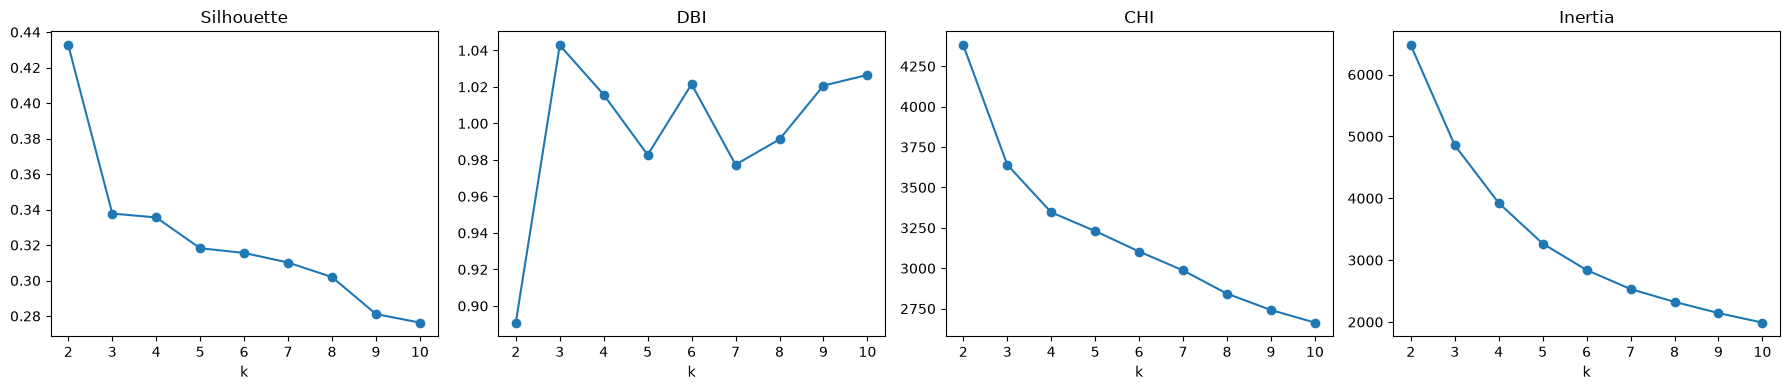

K được chọn theo Silhouette: 2


In [7]:
def scan_k(Xs):
    out = []
    for k in K_RANGE:
        m = KMeans(n_clusters=k, init=INIT, n_init=N_INIT, max_iter=MAX_ITER, tol=TOL, random_state=RANDOM_STATE)
        lab = m.fit_predict(Xs)
        out.append({"k": k, "Silhouette": silhouette_score(Xs, lab), "DBI": davies_bouldin_score(Xs, lab),
                    "CHI": calinski_harabasz_score(Xs, lab), "Inertia": m.inertia_})
    return pd.DataFrame(out)

metrics = scan_k(X_scaled)
display(metrics.round(4))
best_k = int(metrics.loc[metrics["Silhouette"].idxmax(), "k"])

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ["Silhouette", "DBI", "CHI", "Inertia"]):
    ax.plot(metrics["k"], metrics[col], marker="o"); ax.set_xlabel("k"); ax.set_title(col)
plt.tight_layout()
fig.savefig("figures/kmeans_metrics.png", dpi=300, bbox_inches="tight")
plt.show()
print("K được chọn theo Silhouette:", best_k)

**Nhận xét:**

* Silhouette, DBI, CHI đều tính trên `X_scaled`, đúng không gian đã dùng để fit (tránh tính trên dữ liệu chưa scale như một số lần chạy trước, làm Silhouette bị thổi phồng).
* Silhouette cao nhất ở **k = 2 (0,4326)**, từ k = 3 trở đi tụt xuống 0,34–0,28 và giảm dần; DBI thấp nhất cũng ở k = 2 (0,8909). CHI giảm đều theo k và Inertia giảm đều, không có khuỷu rõ.
* Cấu trúc tách rõ nhất là hai nhóm; chia mịn hơn không cho cụm tách tốt hơn, cho thấy dữ liệu RFM giống một dải liên tục.

## Train model với k được chọn

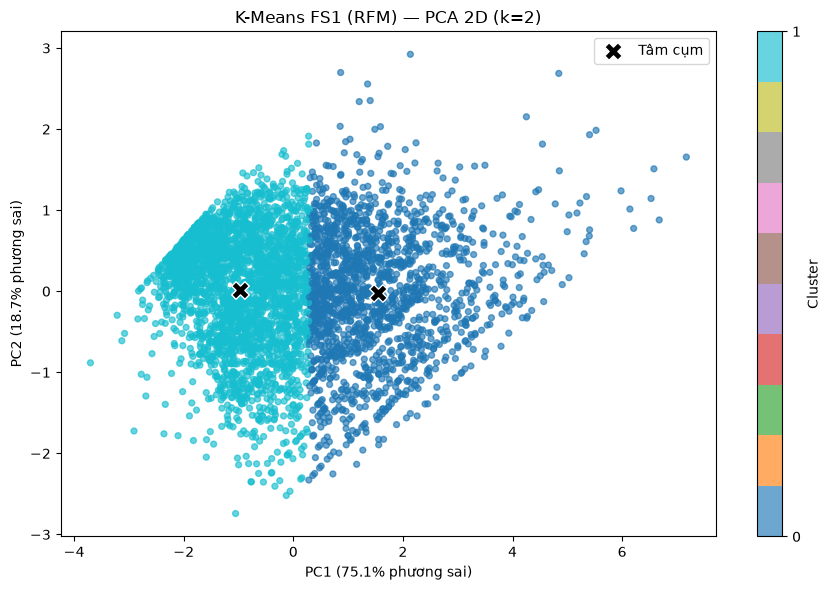

In [8]:
model = KMeans(n_clusters=best_k, init=INIT, n_init=N_INIT, max_iter=MAX_ITER, tol=TOL, random_state=RANDOM_STATE)
labels = model.fit_predict(X_scaled)
result = rfm.assign(cluster=labels)

pca = PCA(n_components=2)
coords = pca.fit_transform(X_scaled)
centers_2d = pca.transform(model.cluster_centers_)
fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(coords[:, 0], coords[:, 1], c=labels, cmap="tab10", s=18, alpha=0.65, rasterized=True)
ax.scatter(centers_2d[:, 0], centers_2d[:, 1], c="black", marker="X", s=160, edgecolors="white", label="Tâm cụm")
ax.set_title(f"K-Means FS1 (RFM) — PCA 2D (k={best_k})")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} phương sai)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} phương sai)")
ax.legend(); fig.colorbar(sc, ax=ax, label="Cluster", ticks=sorted(np.unique(labels))); fig.tight_layout()
fig.savefig("figures/kmeans_clusters_pca.png", dpi=300, bbox_inches="tight")
plt.show()

## Hồ sơ cụm

,n,R,F,M,revenue,pct,rev_pct,group
cluster,,,,,,,,
0,1669,17.0,6.0,2062.7,7584592.77,38.47,85.11,Giá trị cao
1,2669,96.0,1.0,363.7,1326815.13,61.53,14.89,Giá trị thấp


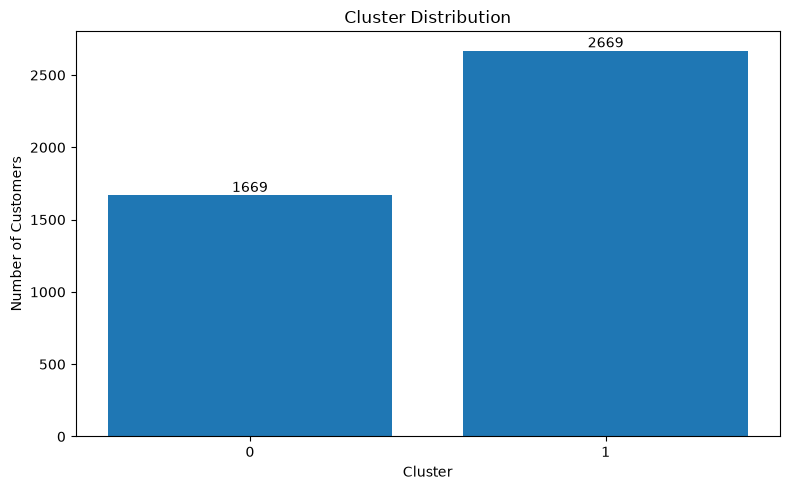

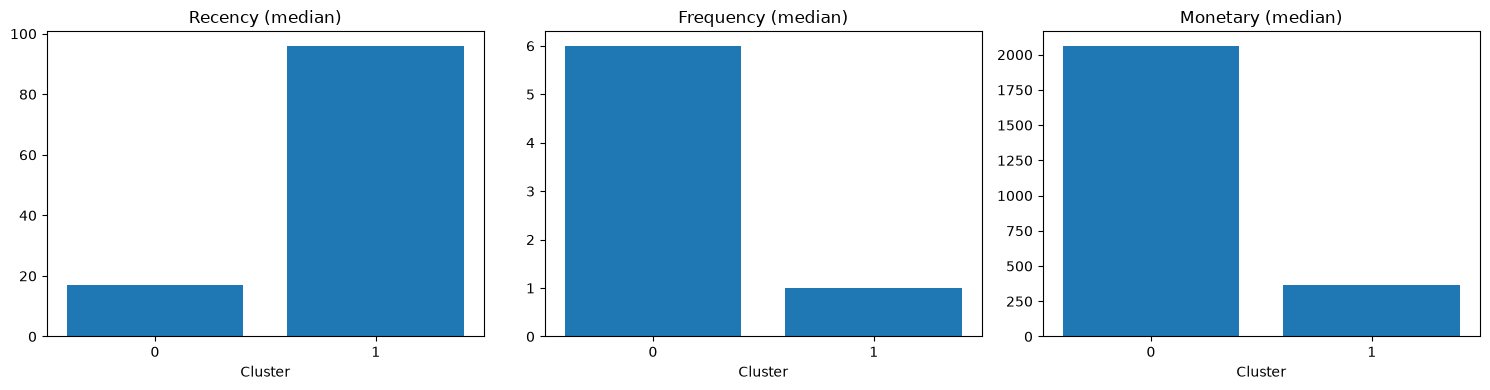

In [9]:
prof = result.groupby("cluster").agg(n=("CustomerID", "size"), R=("Recency", "median"),
                                     F=("Frequency", "median"), M=("Monetary", "median"),
                                     revenue=("Monetary", "sum"))
prof["pct"] = prof["n"] / prof["n"].sum() * 100
prof["rev_pct"] = prof["revenue"] / prof["revenue"].sum() * 100
rank = prof["M"].rank(method="first").astype(int)          # 1 = Monetary median thấp nhất
prof["group"] = ["Giá trị thấp" if (best_k == 2 and r == 1) else "Giá trị cao" if (best_k == 2) else f"Nhóm Monetary hạng {r}"
                 for r in rank]
display(prof.round(2))

cnt = prof["n"]
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(cnt.index, cnt.values); ax.set_title("Cluster Distribution"); ax.set_xlabel("Cluster")
ax.set_ylabel("Number of Customers"); ax.set_xticks(cnt.index)
for i, c in zip(cnt.index, cnt.values): ax.text(i, c, str(c), ha="center", va="bottom")
plt.tight_layout(); fig.savefig("figures/kmeans_cluster_distribution.png", dpi=300); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (col, name) in zip(axes, [("R", "Recency"), ("F", "Frequency"), ("M", "Monetary")]):
    ax.bar(prof.index, prof[col]); ax.set_title(f"{name} (median)"); ax.set_xlabel("Cluster"); ax.set_xticks(prof.index)
plt.tight_layout(); fig.savefig("figures/kmeans_rfm_comparison.png", dpi=300); plt.show()

**Nhận xét:**

* Cụm 0 "Giá trị cao": 1.669 khách (38,47%), Recency trung vị 17 ngày, Frequency 6, Monetary 2.062,7; đóng góp **85,11% doanh thu**.
* Cụm 1 "Giá trị thấp": 2.669 khách (61,53%), Recency 96 ngày, Frequency 1, Monetary 363,7; chỉ 14,89% doanh thu.
* Đây là mô tả giá trị mua lịch sử, không phải dự báo. k = 2 còn thô cho marketing; cần xem k = 3–5 ở các thí nghiệm sau.

## Đối chiếu baseline và độ ổn định

In [10]:
# Baseline = cùng pipeline nhưng xóa dòng trùng hoàn toàn (khác biệt tiền xử lý duy nhất cần kiểm tra)
rfm_b = build_rfm(purchases.drop_duplicates())
Xb, _ = scale(rfm_b)
met_b = scan_k(Xb)
k_b = int(met_b.loc[met_b["Silhouette"].idxmax(), "k"])
lab_b = KMeans(n_clusters=k_b, init=INIT, n_init=N_INIT, max_iter=MAX_ITER, tol=TOL, random_state=RANDOM_STATE).fit_predict(Xb)

assert (rfm_b["CustomerID"].values == rfm["CustomerID"].values).all()
conf = pd.crosstab(labels, lab_b).values
r_, c_ = linear_sum_assignment(-conf)
moved = int(len(labels) - conf[r_, c_].sum())
sil_b = met_b.loc[met_b["k"] == k_b, "Silhouette"].iloc[0]
print(f"Baseline-policy: k={k_b}, Silhouette={sil_b:.4f}, kích thước cụm={sorted(np.bincount(lab_b).tolist())}")
print(f"FS1            : k={best_k}, Silhouette={metrics.loc[metrics.k==best_k,'Silhouette'].iloc[0]:.4f}, kích thước cụm={sorted(np.bincount(labels).tolist())}")
ari_base = adjusted_rand_score(labels, lab_b)
print(f"ARI(FS1, baseline-policy) = {ari_base:.4f} | số khách đổi cụm = {moved}")
print("Max |ΔMonetary| giữa hai cách xử lý:", float((rfm['Monetary'] - rfm_b['Monetary']).abs().max()))

seeds = [1, 7, 13, 21, 99]
aris = [adjusted_rand_score(labels, KMeans(n_clusters=best_k, init=INIT, n_init=N_INIT, max_iter=MAX_ITER,
        tol=TOL, random_state=s).fit_predict(X_scaled)) for s in seeds]
print("ARI giữa seed 42 và", seeds, "=", np.round(aris, 4))

Baseline-policy: k=2, Silhouette=0.4325, kích thước cụm=[1668, 2670]
FS1            : k=2, Silhouette=0.4326, kích thước cụm=[1669, 2669]
ARI(FS1, baseline-policy) = 0.9991 | số khách đổi cụm = 1
Max |ΔMonetary| giữa hai cách xử lý: 666.5400000000009
ARI giữa seed 42 và [1, 7, 13, 21, 99] = [1.     0.9991 1.     0.9991 0.9991]


**Nhận xét:**

* Pipeline baseline được tái lập đúng: k = 2, Silhouette 0,4325, cụm 1.668 / 2.670, khớp báo cáo baseline (0,432509; 1.668 / 2.670).
* FS1 so với baseline: **ARI = 0,9991, chỉ 1 khách đổi cụm**; Silhouette 0,4326 so với 0,4325. Giữ 5.192 dòng trùng (khoảng 0,27% doanh thu) hầu như không đổi phân cụm RFM.
* ARI giữa các seed từ 0,9991 đến 1,0: kết quả ổn định theo seed.
* Kết luận: FS1 đạt vai trò **đối chứng**, và làm mốc để so sánh FS2–FS4. Muốn khác baseline thì phải thêm thông tin (feature), không phải nới tiền xử lý.

## Lưu tham số, mô hình và nhật ký

In [11]:
from openpyxl import Workbook
from openpyxl.styles import Alignment, Font

print("Silhouette:", silhouette_score(X_scaled, labels))
print("DBI:", davies_bouldin_score(X_scaled, labels))
print("CHI:", calinski_harabasz_score(X_scaled, labels))
print("Inertia:", model.inertia_)

with open("kmeans_params.json", "w") as f:
    json.dump(model.get_params(), f, indent=4)
joblib.dump(model, "kmeans_model.pkl")
joblib.dump(scaler, "scaler.pkl")                       # cần cùng log1p để áp dụng cho khách mới
result[["CustomerID", "cluster"]].to_csv("data/customer_clusters.csv", index=False)

# ---- Sheet 1: bố cục theo Working_details_KMeans_RFM.xlsx của Hiếu ----
wb = Workbook(); ws = wb.active; ws.title = "KMeans_FS1"
B = Font(name="Calibri", size=11, bold=True)
ws["A1"] = "THÍ NGHIỆM K-MEANS — FEATURE FS1 (RFM, tiền xử lý P-keep)"; ws["A1"].font = Font(name="Calibri", size=15, bold=True)
ws.merge_cells("A1:J1"); ws.row_dimensions[1].height = 33
ws["A2"] = "Trạng thái"; ws["B2"] = "Đã chạy mô hình; chỉ số tính trên X_scaled (log1p + StandardScaler). Thử nghiệm, chưa phải quyết định chính thức của nhóm"
ws.merge_cells("B2:J2"); ws.row_dimensions[2].height = 24
for c, v in {"A4": "Thiết lập", "B4": "Giá trị", "D4": "Tham số khác", "E4": "Giá trị"}.items():
    ws[c] = v; ws[c].font = B
ws.row_dimensions[4].height = 25
left = [("Feature", "Recency, Frequency, Monetary"), ("Dữ liệu train", "X_scaled (log1p + StandardScaler)"),
        ("K được chọn", best_k), ("random_state", RANDOM_STATE), ("init", INIT), ("n_init", N_INIT)]
right = [("max_iter", MAX_ITER), ("tol", TOL), ("Tổng khách hàng", len(rfm)), ("Số cụm", best_k),
         ("Tiền xử lý", "P-keep (sheet TienXuLy)")]
for i, (a, b) in enumerate(left, start=5): ws[f"A{i}"], ws[f"B{i}"] = a, b
for i, (a, b) in enumerate(right, start=5): ws[f"D{i}"], ws[f"E{i}"] = a, b
for j, h in enumerate(["k", "Silhouette", "DBI", "CHI", "Inertia", "Nhận xét"]):
    c = ws.cell(row=12, column=1 + j, value=h); c.font = B
ws.row_dimensions[12].height = 25
for i, r in enumerate(metrics.itertuples(index=False), start=13):
    ws.cell(i, 1, int(r.k))
    for j, v in enumerate([r.Silhouette, r.DBI, r.CHI, r.Inertia], start=2):
        ws.cell(i, j, round(float(v), 4)).number_format = "0.0000"
    if int(r.k) == best_k: ws.cell(i, 6, "k được chọn")
for j, h in enumerate(["Cụm", "Nhóm khách hàng", "Số khách", "Tỷ lệ (%)", "Recency (median)",
                       "Frequency (median)", "Monetary (median)", "Tỷ trọng doanh thu (%)"]):
    c = ws.cell(row=24, column=1 + j, value=h); c.font = B
ws.row_dimensions[24].height = 25
for i, (cl, r) in enumerate(prof.iterrows(), start=25):
    vals = [int(cl), r["group"], int(r["n"]), round(r["pct"], 2), float(r["R"]), float(r["F"]), round(r["M"], 2), round(r["rev_pct"], 2)]
    for j, v in enumerate(vals, start=1): ws.cell(i, j, v)
    ws.cell(i, 4).number_format = ws.cell(i, 7).number_format = ws.cell(i, 8).number_format = "0.00"
for col, w in zip("ABCDEFGHI", [16, 22, 17, 19, 20, 21, 25, 22, 13]): ws.column_dimensions[col].width = w
ws.freeze_panes = "A5"

# ---- Sheet 2: đối soát tiền xử lý và đối chiếu baseline ----
w2 = wb.create_sheet("TienXuLy")
w2["A1"] = "Đối soát số dòng P-keep (từ raw)"; w2["A1"].font = Font(name="Calibri", size=13, bold=True)
for j, h in enumerate(accounting.columns, start=1): w2.cell(3, j, h).font = B
for i, row in enumerate(accounting.itertuples(index=False), start=4):
    for j, v in enumerate(row, start=1): w2.cell(i, j, v.item() if hasattr(v, "item") else v)
r0 = 4 + len(accounting) + 2
w2.cell(r0, 1, "Đối chiếu baseline (cùng pipeline, chỉ khác xóa dòng trùng)").font = B
cmp_rows = [("Số khách", len(rfm_b), len(rfm)), ("k chọn theo Silhouette", k_b, best_k),
            ("Silhouette tại k chọn", round(float(sil_b), 4), round(float(metrics.loc[metrics.k == best_k, "Silhouette"].iloc[0]), 4)),
            ("ARI (FS1 vs baseline)", round(float(ari_base), 4), ""), ("Số khách đổi cụm", moved, ""),
            ("ARI min giữa các seed (FS1)", round(float(min(aris)), 4), "")]
w2.cell(r0 + 1, 1, "Chỉ tiêu").font = w2.cell(r0 + 1, 2, "Baseline-policy").font = w2.cell(r0 + 1, 3, "FS1").font = B
for i, row in enumerate(cmp_rows, start=r0 + 2):
    for j, v in enumerate(row, start=1): w2.cell(i, j, v)
for col, w in zip("ABCDEFG", [48, 18, 18, 14, 14, 14, 16]): w2.column_dimensions[col].width = w
wb.save("Working_details_KMeans_FS1.xlsx")
print("Đã lưu nhật ký.")

Silhouette: 0.43262378515578903
DBI: 0.8908510455594781
CHI: 4380.0168159493205
Inertia: 6474.146442729575
Đã lưu nhật ký.


**Nhận xét:** Đã lưu tham số, mô hình, `scaler.pkl` (cần cùng log1p để áp dụng cho khách mới), nhãn cụm và workbook nhật ký (sheet `KMeans_FS1` theo mẫu của Hiếu, thêm sheet `TienXuLy`).